# Phase 2: comparing training runs

Every run of `notebooks/phase2.ipynb` saves its policy as `results/models/phase2_<name>.pt`. This notebook puts runs side by side **on the same benchmark scenes and the same starts**, so any difference comes from the training, not from luck.

All GIFs here are **inference**: the trained weights are frozen, and each drone runs the policy on what it sees, step by step, in the same simulator used for training. No learning happens while they play.

| Section | What it compares |
|---|---|
| 1 | Setup: which runs |
| 2 | Training: length, early stopping, curves |
| 3 | Benchmark: shape error, crowding and evenness in every cell |
| 4 | Spacing between neighbors (the thing the spacing term targets) |
| 5 | Side-by-side GIFs on identical scenes |
| 6 | Summary |

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, data/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from swarm import viz
from swarm.config import load_config
from swarm.dataset import D_MIN_FRAC, GRID, load_cell, sample_strokes, text_strokes, total_length, transform
from swarm.losses import chamfer, pairwise_sq_dist, spacing_cv
from swarm.policy import SharedMLP
from swarm.sim import rollout_closed_loop
from swarm.train import evaluate_benchmark, evaluate_cell, overall_ratio

cfg = load_config("configs/default.yaml")
RUNS = ["baseline", "spacing"]               # names of finished phase2.ipynb runs to compare
COLORS = {"baseline": "#8A94A6", "spacing": "#2F6DB5"}
GIFS, FIGS = Path("results/gifs"), Path("results/figures")
policies = {r: SharedMLP.load(f"results/models/phase2_{r}.pt").eval() for r in RUNS}
histories = {}
for r in RUNS:
    h = Path(f"runs/phase2_{r}/history.json")
    histories[r] = json.loads(h.read_text()) if h.exists() else None
summary = {r: {} for r in RUNS}
print("comparing:", RUNS)

comparing: ['baseline', 'spacing']


## 2. Training

run         iterations  stopped early  minutes  best ×opt  at it
baseline          3000             no     16.0       2.23   3000
spacing           3000             no     16.2       2.19   2250


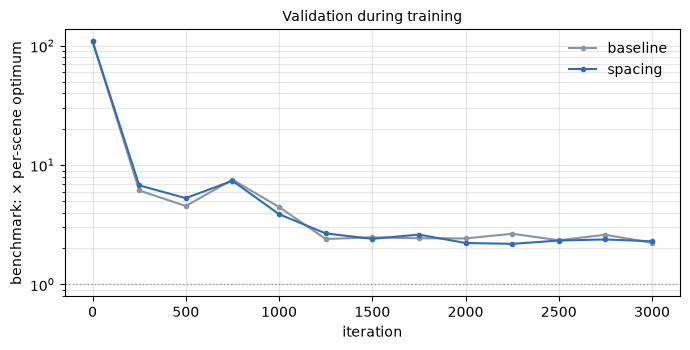

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.6))
print(f"{'run':10s}{'iterations':>12s}{'stopped early':>15s}{'minutes':>9s}{'best ×opt':>11s}{'at it':>7s}")
for r in RUNS:
    h = histories[r]
    if h is None:
        print(f"{r:10s}  (no runs/phase2_{r}/history.json: training log not available)")
        continue
    val = h["val"]
    best = min(val, key=lambda v: v["ratio"])
    stop = h.get("stopped_at")
    summary[r].update(iterations=len(h["train"]), minutes=h["train"][-1]["time"] / 60, stopped_at=stop,
                      best_val=best["ratio"], best_it=best["it"])
    print(f"{r:10s}{len(h['train']):12d}{str(stop) if stop else 'no':>15s}{h['train'][-1]['time'] / 60:9.1f}"
          f"{best['ratio']:11.2f}{best['it']:7d}")
    ax.semilogy([v["it"] for v in val], [v["ratio"] for v in val], "o-", ms=3, color=COLORS.get(r), label=r)
ax.axhline(1, color="0.6", ls=":", lw=1)
ax.set_xlabel("iteration"); ax.set_ylabel("benchmark: × per-scene optimum"); ax.grid(alpha=0.3, which="both")
ax.legend(frameon=False); ax.set_title("Validation during training", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "phase2_compare_training.png"); plt.show()

## 3. Benchmark: every cell, both splits

Three measures per cell, lower is better for all:
- **× optimum**: final shape error ÷ the per-scene optimum (1× = as good as optimizing that scene directly)
- **close pairs**: drone pairs closer than the collision distance at the end
- **unevenness**: std ÷ mean of each drone's nearest-neighbor distance (0 = perfectly even spacing)

In [3]:
rows = {r: {sp: evaluate_benchmark(policies[r], cfg, sp) for sp in ("train", "heldout")} for r in RUNS}
for r in RUNS:
    summary[r].update({
        "ratio_train": overall_ratio(rows[r]["train"]), "ratio_heldout": overall_ratio(rows[r]["heldout"]),
        "close_pairs": float(np.mean([c["close_pairs"] for c in rows[r]["train"] + rows[r]["heldout"]])),
        "unevenness": float(np.mean([c["uniformity"] for c in rows[r]["train"] + rows[r]["heldout"]]))})
opt_close = np.mean([c["oracle_close_pairs"] for c in rows[RUNS[0]]["train"] + rows[RUNS[0]]["heldout"]])
opt_unif = np.mean([c["oracle_uniformity"] for c in rows[RUNS[0]]["train"] + rows[RUNS[0]]["heldout"]])
print(f"{'':12s}" + "".join(f"{r:>12s}" for r in RUNS) + f"{'optimum':>12s}")
for key, label in [("ratio_train", "×opt train"), ("ratio_heldout", "×opt held"), ("close_pairs", "close pairs"),
                   ("unevenness", "unevenness")]:
    ref = {"close_pairs": f"{opt_close:12.2f}", "unevenness": f"{opt_unif:12.3f}"}.get(key, f"{'1.00':>12s}")
    print(f"{label:12s}" + "".join(f"{summary[r][key]:12.3f}" for r in RUNS) + ref)

print("\nper cell (training-family scenes):")
print(f"{'cell':>13s}" + "".join(f"{'×opt ' + r:>16s}" for r in RUNS) + "".join(f"{'close ' + r:>16s}" for r in RUNS)
      + "".join(f"{'uneven ' + r:>17s}" for r in RUNS) + f"{'uneven opt':>12s}")
for i, (n, m) in enumerate(GRID):
    rr = [rows[r]["train"][i] for r in RUNS]
    print(f"  N={n:3d} M={m:4d}" + "".join(f"{x['ratio']:16.2f}" for x in rr) + "".join(f"{x['close_pairs']:16.2f}" for x in rr)
          + "".join(f"{x['uniformity']:17.3f}" for x in rr) + f"{rr[0]['oracle_uniformity']:12.3f}")

                baseline     spacing     optimum
×opt train         2.228       2.186        1.00
×opt held          2.248       2.339        1.00
close pairs        6.136       3.184        2.25
unevenness         0.433       0.307       0.340

per cell (training-family scenes):
         cell   ×opt baseline    ×opt spacing  close baseline   close spacing  uneven baseline   uneven spacing  uneven opt
  N=  8 M=   8            6.47            6.26            0.66            0.09            0.359            0.182       0.472
  N=  8 M=  16            1.53            1.42            0.25            0.00            0.353            0.170       0.235
  N=  8 M=  32            1.42            1.27            0.22            0.00            0.288            0.176       0.131
  N=  8 M=  64            1.30            1.37            0.03            0.00            0.140            0.126       0.082
  N= 16 M=  16            4.58            4.46            2.44            0.81            0.520

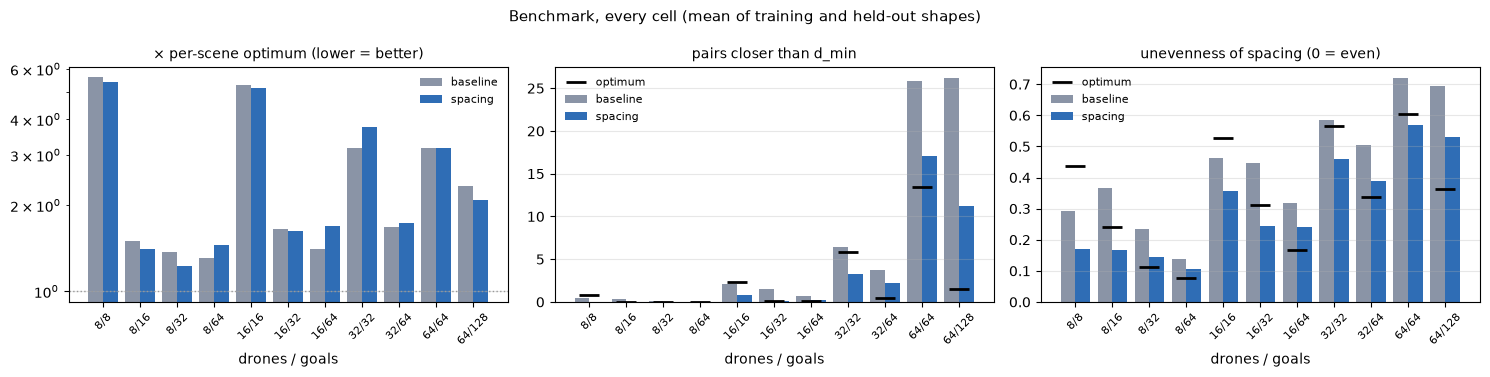

In [4]:
labels = [f"{n}/{m}" for n, m in GRID]
x = np.arange(len(GRID)); w = 0.8 / len(RUNS)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for k, (key, title, log) in enumerate([("ratio", "× per-scene optimum (lower = better)", True),
                                        ("close_pairs", "pairs closer than d_min", False),
                                        ("uniformity", "unevenness of spacing (0 = even)", False)]):
    ax = axs[k]
    for j, r in enumerate(RUNS):
        vals = [(a[key] + b[key]) / 2 for a, b in zip(rows[r]["train"], rows[r]["heldout"])]
        ax.bar(x + (j - (len(RUNS) - 1) / 2) * w, vals, w, color=COLORS.get(r), label=r)
    if key == "uniformity":
        ax.plot(x, [(a["oracle_uniformity"] + b["oracle_uniformity"]) / 2 for a, b in
                    zip(rows[RUNS[0]]["train"], rows[RUNS[0]]["heldout"])], "k_", ms=14, mew=2, label="optimum")
    if key == "close_pairs":
        ax.plot(x, [(a["oracle_close_pairs"] + b["oracle_close_pairs"]) / 2 for a, b in
                    zip(rows[RUNS[0]]["train"], rows[RUNS[0]]["heldout"])], "k_", ms=14, mew=2, label="optimum")
    if log:
        ax.set_yscale("log"); ax.axhline(1, color="0.6", ls=":", lw=1)
    ax.set_xticks(x, labels, rotation=45, fontsize=8); ax.set_xlabel("drones / goals")
    ax.set_title(title, fontsize=10); ax.grid(alpha=0.3, axis="y"); ax.legend(frameon=False, fontsize=8)
fig.suptitle("Benchmark, every cell (mean of training and held-out shapes)", fontsize=11)
fig.tight_layout(); fig.savefig(FIGS / "phase2_compare_cells.png"); plt.show()

## 4. Spacing between neighbors

For every drone at the end of every benchmark scene: the distance to its nearest neighbor, divided by the scene's ideal spacing *s* (outline length ÷ N). Evenly spread drones sit near 1. A pile at 0 means clumps; a long tail means gaps.

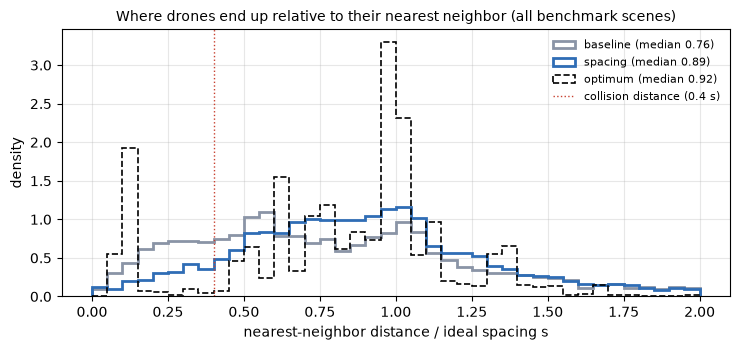

baseline   drones closer than 0.4 s to a neighbor: 20.6%
spacing    drones closer than 0.4 s to a neighbor: 9.9%
optimum    drones closer than 0.4 s to a neighbor: 13.9%


In [5]:
def nn_over_s(policy_or_none, split):
    out = []
    for n, m in GRID:
        cell = load_cell(n, m, split)
        final = cell["oracle_final"] if policy_or_none is None else evaluate_cell(policy_or_none, cell, cfg)["traj"][:, -1]
        d = torch.sqrt(pairwise_sq_dist(final, final)) + torch.eye(n) * 1e9
        s = cell["d_min"] / D_MIN_FRAC
        out.append((d.min(dim=2).values / s[:, None]).flatten())
    return torch.cat(out).numpy()

dists = {r: np.concatenate([nn_over_s(policies[r], sp) for sp in ("train", "heldout")]) for r in RUNS}
dists["optimum"] = np.concatenate([nn_over_s(None, sp) for sp in ("train", "heldout")])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(0, 2, 41)
for r, d in dists.items():
    ax.hist(d, bins=bins, histtype="step", lw=2 if r != "optimum" else 1.2, density=True,
            color=COLORS.get(r, "k"), ls="-" if r != "optimum" else "--", label=f"{r} (median {np.median(d):.2f})")
    if r in summary:
        summary[r]["clumped_frac"] = float((d < 0.4).mean())
ax.axvline(0.4, color="#C8402F", lw=1, ls=":", label="collision distance (0.4 s)")
ax.set_xlabel("nearest-neighbor distance / ideal spacing s"); ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.3)
ax.set_title("Where drones end up relative to their nearest neighbor (all benchmark scenes)", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "phase2_compare_spacing.png"); plt.show()
for r in RUNS:
    print(f"{r:10s} drones closer than 0.4 s to a neighbor: {100 * summary[r]['clumped_frac']:.1f}%")
print(f"{'optimum':10s} drones closer than 0.4 s to a neighbor: {100 * (dists['optimum'] < 0.4).mean():.1f}%")

## 5. Side by side on identical scenes

Each column is one scene (same start, same goals); the rows are the runs. Inference only: frozen weights, 150 steps.

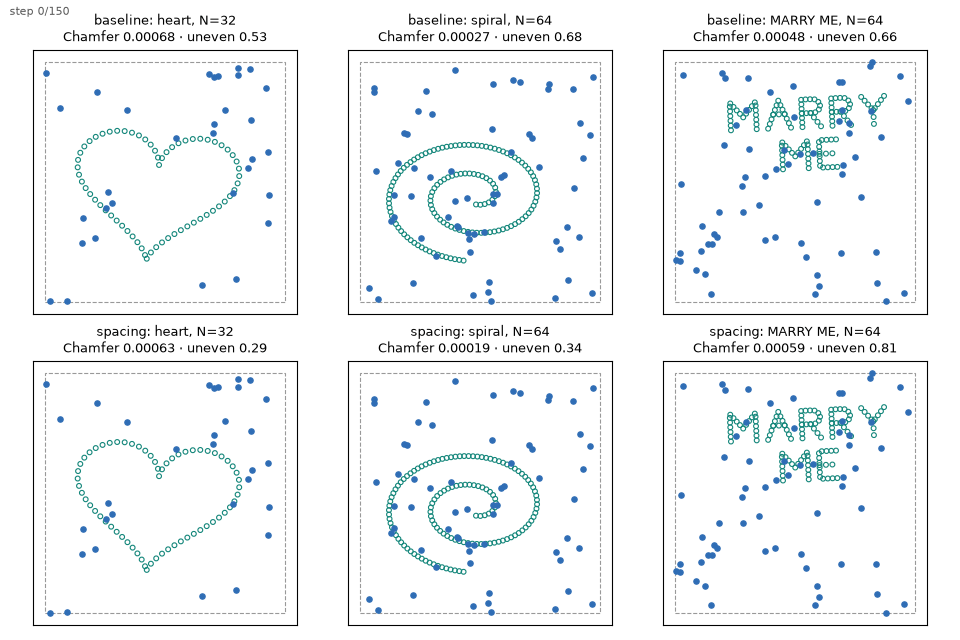

In [6]:
def scene_from_cell(n, m, split, family):
    c = load_cell(n, m, split); i = c["family"].index(family)
    return c["start"][i:i + 1], c["goals"][i:i + 1], c["d_min"][i:i + 1]

def marry_me(n=64, m=128):
    st = transform(text_strokes("MARRY\nME"), np.random.default_rng(0), upright=True)
    Q = torch.tensor(sample_strokes(st, m)[None], dtype=torch.float32)
    p0 = torch.rand(1, n, 2, generator=torch.Generator().manual_seed(0)) - 0.5
    return p0, Q, torch.tensor([D_MIN_FRAC * total_length(st) / n])

def side_by_side(scenes, path, steps=150):
    trajs, goals, titles = [], [], []
    for r in RUNS:
        for name, (p0, Q, dm) in scenes:
            with torch.no_grad():
                tr, _ = rollout_closed_loop(p0, torch.zeros_like(p0), Q, dm, policies[r].act, cfg, steps=steps)
            err, unev = chamfer(tr[:, -1], Q).item(), spacing_cv(tr[:, -1]).item()
            trajs.append(tr[0]); goals.append(Q[0])
            titles.append(f"{r}: {name}\nChamfer {err:.5f} · uneven {unev:.2f}")
    return viz.save_gif_grid(trajs, goals, path, titles=titles, cols=len(scenes), panel=3.2)

heldout = [("heart, N=32", scene_from_cell(32, 64, "heldout", "heart")),
           ("spiral, N=64", scene_from_cell(64, 128, "heldout", "spiral")),
           ("MARRY ME, N=64", marry_me())]
gif = side_by_side(heldout, GIFS / "phase2_compare_heldout.gif")
display(Image(filename=gif))

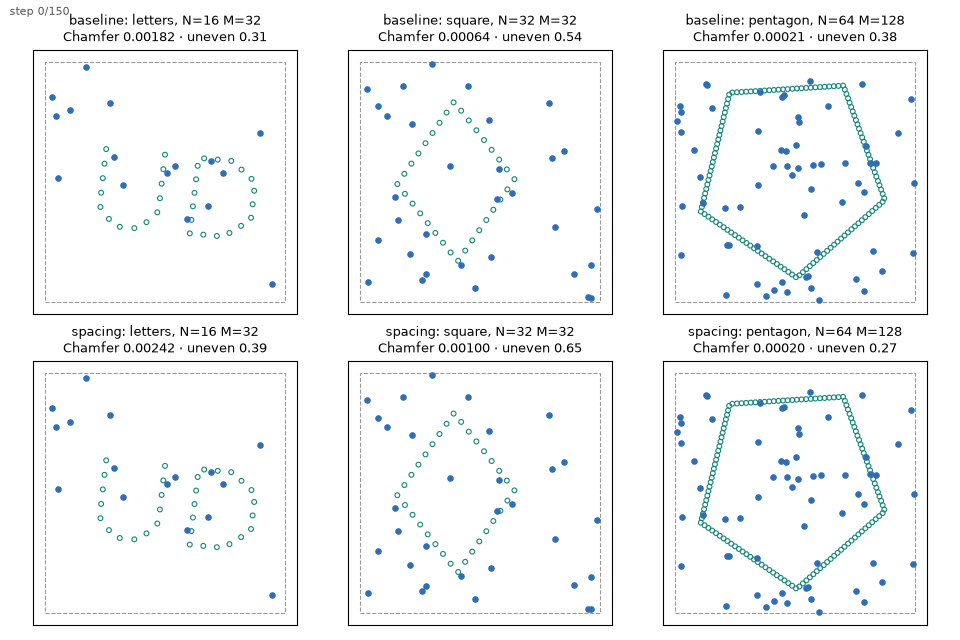

In [7]:
cells = [("letters, N=16 M=32", scene_from_cell(16, 32, "train", "letters")),
         ("square, N=32 M=32", scene_from_cell(32, 32, "train", "square")),
         ("pentagon, N=64 M=128", scene_from_cell(64, 128, "train", "pentagon"))]
gif = side_by_side(cells, GIFS / "phase2_compare_cells.gif")
display(Image(filename=gif))

## 6. Summary

In [9]:
Path("results").mkdir(exist_ok=True)
Path("results/phase2_compare.json").write_text(json.dumps(summary, indent=1))
for r in RUNS:
    s = summary[r]
    print(f"{r}: ×opt {s['ratio_train']:.2f} (held-out {s['ratio_heldout']:.2f}), close pairs {s['close_pairs']:.1f}, "
          f"unevenness {s['unevenness']:.3f}, clumped {100 * s['clumped_frac']:.1f}%"
          + (f", {s['iterations']} iterations in {s['minutes']:.0f} min" if "iterations" in s else ""))
print("saved results/phase2_compare.json")

baseline: ×opt 2.23 (held-out 2.25), close pairs 6.1, unevenness 0.433, clumped 20.6%, 3000 iterations in 16 min
spacing: ×opt 2.19 (held-out 2.34), close pairs 3.2, unevenness 0.307, clumped 9.9%, 3000 iterations in 16 min
saved results/phase2_compare.json
